In [1]:
import pandas as pd

sales_data_deduped = pd.read_csv(
    r"D:\Portfolio\retail-online-analysis\data\sales_data_deduped.csv",
    dtype={'InvoiceNo': 'string'}
)

sales_data_deduped['InvoiceDate'] = pd.to_datetime(sales_data_deduped['InvoiceDate'])
sales_data_deduped['CustomerID'] = sales_data_deduped['CustomerID'].astype('Int64')

sales_data_deduped['Revenue'] = sales_data_deduped['Quantity'] * sales_data_deduped['UnitPrice']

In [2]:
# 1. Top 10 customers by revenue
customer_sales = sales_data_deduped[
    sales_data_deduped['CustomerID'].notna()
].copy()

top_customers_revenue = (
    customer_sales.groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Revenue:", top_customers_revenue)

Top 10 Customers by Revenue: CustomerID
14646    280206.02
18102    259657.30
17450    194390.79
16446    168472.50
14911    143711.17
12415    124914.53
14156    117210.08
17511     91062.38
16029     80850.84
12346     77183.60
Name: Revenue, dtype: float64


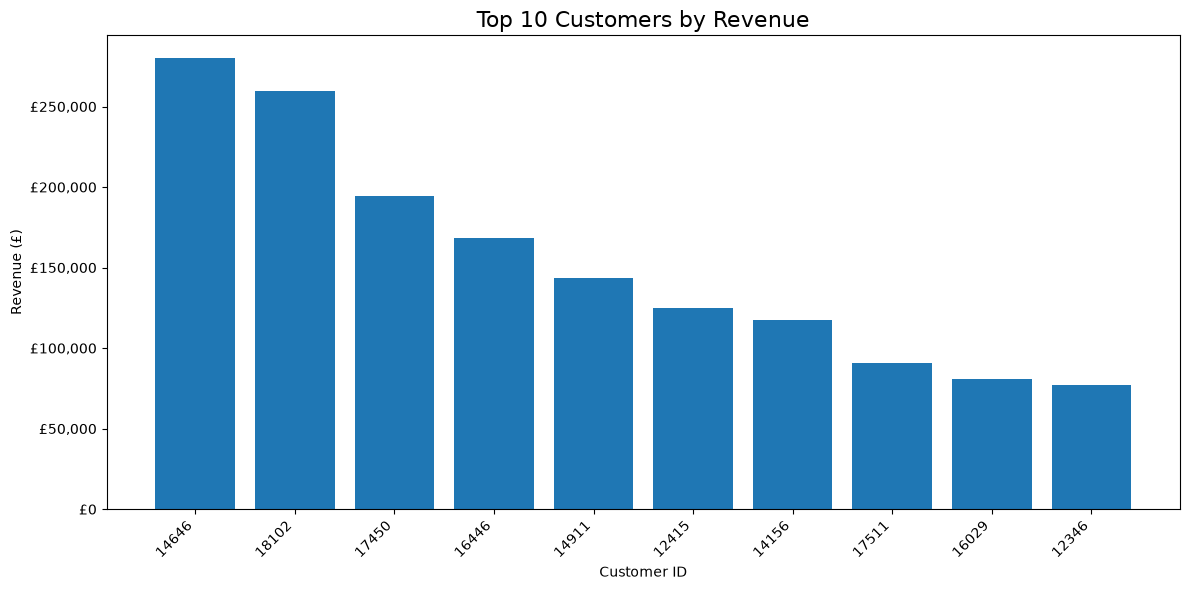

In [3]:
# 2. Visualize the top 10 customers by revenue with a vertical bar chart
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.figure(figsize=(12, 6))

plt.bar(
    top_customers_revenue.index.astype(str),
    top_customers_revenue.values
)

plt.title('Top 10 Customers by Revenue', fontsize=16)
plt.xlabel('Customer ID')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter('£{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [4]:
# 3. Top 10 customers by quantity
top_customers_quantity = (
    customer_sales.groupby('CustomerID')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Quantity:", top_customers_quantity)

Top 10 Customers by Quantity: CustomerID
14646    196915
16446     80997
14911     80240
12415     77374
12346     74215
17450     69973
17511     64549
18102     64124
13694     63312
14298     58343
Name: Quantity, dtype: int64


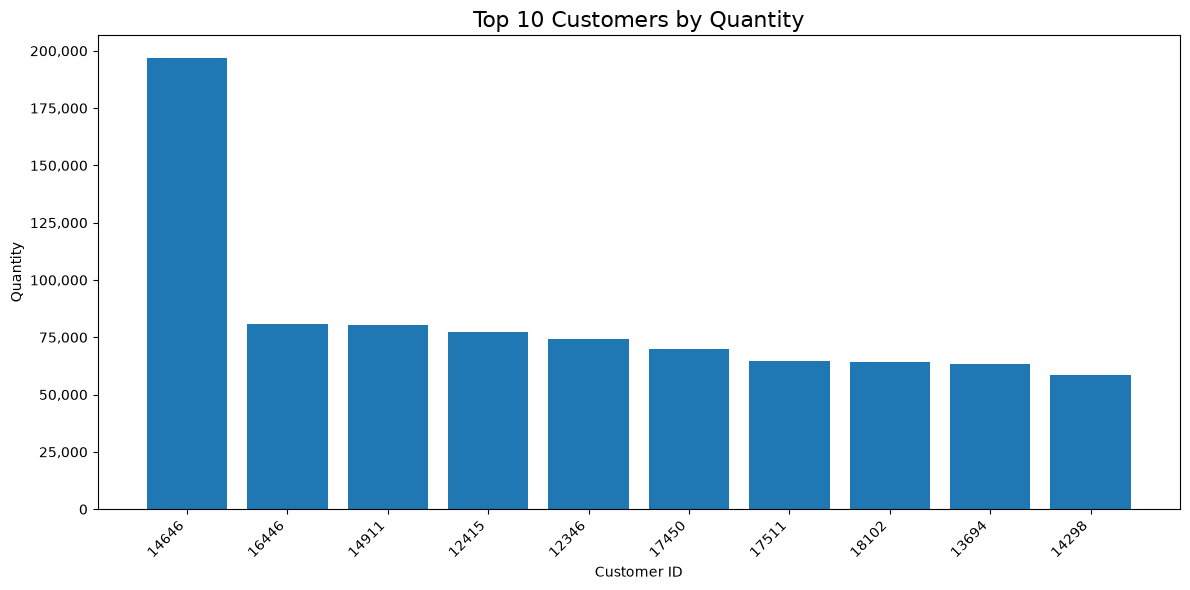

In [5]:
# 4. Visualize the top 10 customers by quantity with a vertical bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    top_customers_quantity.index.astype(str),
    top_customers_quantity.values
)

plt.title('Top 10 Customers by Quantity', fontsize=16)
plt.xlabel('Customer ID')
plt.ylabel('Quantity')
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [6]:
# 5. Top products purchased by a specific customer (CustomerID: 14646)
customer_14646 = sales_data_deduped[
    sales_data_deduped['CustomerID'] == 14646
]

customer_product_summary = (
    customer_14646.groupby('Description')
    .agg(
        Total_Quantity=('Quantity', 'sum'),
        Total_Revenue=('Revenue', 'sum')
    )
    .sort_values('Total_Revenue', ascending=False)
)

print(customer_product_summary.head(10))

                                     Total_Quantity  Total_Revenue
Description                                                       
RABBIT NIGHT LIGHT                             4801        9568.48
ROUND SNACK BOXES SET OF4 WOODLAND             3120        7956.00
SPACEBOY LUNCH BOX                             4492        7415.40
DOLLY GIRL LUNCH BOX                           4096        6758.40
ROUND SNACK BOXES SET OF 4 FRUITS              1584        4039.20
JUMBO BAG RED RETROSPOT                        2000        3468.00
RED TOADSTOOL LED NIGHT LIGHT                  2376        3459.60
REGENCY CAKESTAND 3 TIER                        288        3153.60
5 HOOK HANGER RED MAGIC TOADSTOOL              2016        2923.20
JUMBO BAG WOODLAND ANIMALS                     1500        2629.00


In [7]:
# 10. Top 10 customers by order count
top_customers_order_count = (
    customer_sales.groupby('CustomerID')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print(top_customers_order_count)

CustomerID
12748    209
14911    201
17841    124
13089     97
14606     93
15311     91
12971     86
14646     73
16029     63
13408     62
Name: InvoiceNo, dtype: int64


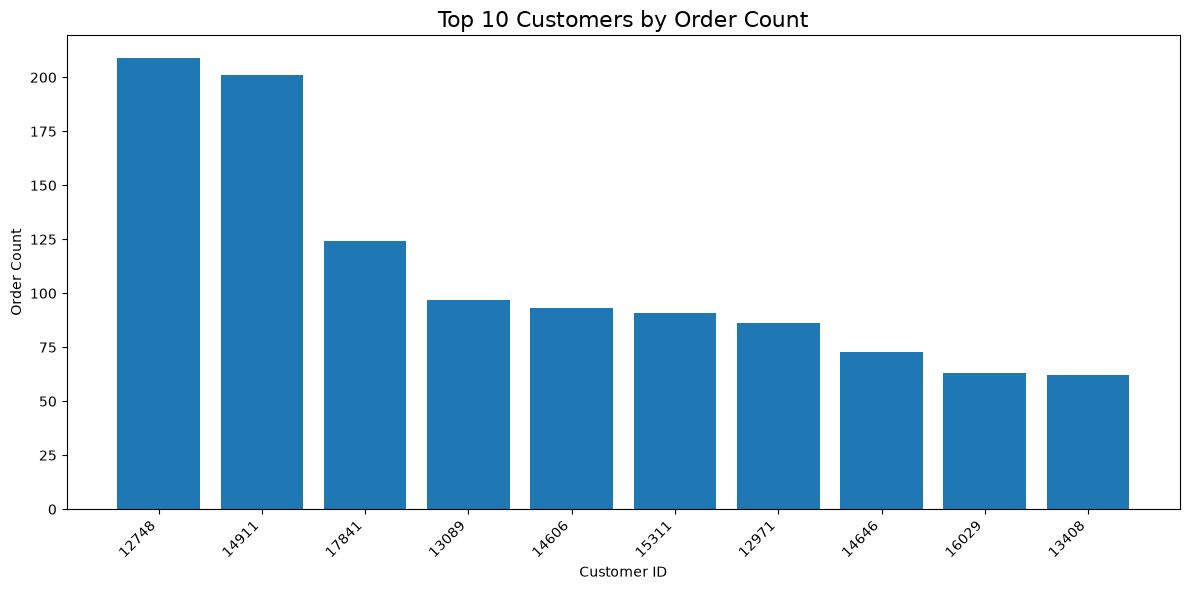

In [8]:
# 11. Visualize the top 10 customers by order count with a vertical bar chart

plt.figure(figsize=(12, 6))

plt.bar(
    top_customers_order_count.index.astype(str),
    top_customers_order_count.values
)

plt.title('Top 10 Customers by Order Count', fontsize=16)
plt.xlabel('Customer ID')
plt.ylabel('Order Count')
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter('{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [9]:
# 12. Customer Summary: Total Revenue, Total Quantity, and Order Count
customer_summary = (
    customer_sales.groupby('CustomerID')
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Order_Count=('InvoiceNo', 'nunique')
    )
)

print(customer_summary.head(10))

            Total_Revenue  Total_Quantity  Order_Count
CustomerID                                            
12346            77183.60           74215            1
12347             4310.00            2458            7
12348             1797.24            2341            4
12349             1757.55             631            1
12350              334.40             197            1
12352             2506.04             536            8
12353               89.00              20            1
12354             1079.40             530            1
12355              459.40             240            1
12356             2811.43            1591            3


In [10]:
# 13. Sort by Total Revenue
customer_summary_sorted_revenue = customer_summary.sort_values(
    by='Total_Revenue',
    ascending=False
)

print(customer_summary_sorted_revenue.head(10))

            Total_Revenue  Total_Quantity  Order_Count
CustomerID                                            
14646           280206.02          196915           73
18102           259657.30           64124           60
17450           194390.79           69973           46
16446           168472.50           80997            2
14911           143711.17           80240          201
12415           124914.53           77374           21
14156           117210.08           57768           55
17511            91062.38           64549           31
16029            80850.84           40108           63
12346            77183.60           74215            1


In [11]:
# 14. Sort by Total Quantity
customer_summary_sorted_quantity = customer_summary.sort_values(
    by='Total_Quantity',
    ascending=False
)

print(customer_summary_sorted_quantity.head(10))

            Total_Revenue  Total_Quantity  Order_Count
CustomerID                                            
14646           280206.02          196915           73
16446           168472.50           80997            2
14911           143711.17           80240          201
12415           124914.53           77374           21
12346            77183.60           74215            1
17450           194390.79           69973           46
17511            91062.38           64549           31
18102           259657.30           64124           60
13694            65039.62           63312           50
14298            51527.30           58343           44


In [12]:
# 15. Sort by Order Count
customer_summary_sorted_order_count = customer_summary.sort_values(
    by='Order_Count',
    ascending=False
)

print(customer_summary_sorted_order_count.head(10))

            Total_Revenue  Total_Quantity  Order_Count
CustomerID                                            
12748            33053.19           25287          209
14911           143711.17           80240          201
17841            40519.84           22834          124
13089            58762.08           31025           97
14606            12076.15            6187           93
15311            60632.75           38147           91
12971            11189.91            9289           86
14646           280206.02          196915           73
16029            80850.84           40108           63
13408            28117.04           16232           62


# Summary

This notebook analyzes the customers who generated the most revenues, quantity, and order count. The analysis uses sales_data_deduped.csv, focusing on total revenue, quantity purchased, and order count. The analysis revealed the following:
| CustomerID | Total_Revenue | Total_Quantity | Order_Count |
|-----------|-------------|---------------:|--------------:|
| 12748 | 33053.19 | 25287 | 209 |
| 14911 | 143711.17 | 80240 | 201 |
| 17841 | 40519.84 | 22834 | 124 |
| 13089 | 58762.08 | 31025 | 97 |
| 14606 | 12076.15 | 6187 | 93 |
| 15311 | 60632.75 | 38147 | 91 |
| 12971 | 11189.91 | 9289 | 86 |
| 14646 | 280206.02 | 196915 | 73 |
| 16029 | 80850.84 | 40108 | 63 |
| 13408 | 28117.04 | 16232 | 62 |

The table above presents the top ten customers based on the analysis.

Among these customers:
- Highest total revenue: Customer 14646, generating £280,206.02.
- Highest total quantity: Customer 14646, purchasing 196,915 units.
- Highest order count: Customer 12748, with 209 orders.